## Traffic Stop

Define our Main functions: $u(\rho)$, $F(\rho)$, $a(\rho)$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

road_length = 11.0
rho_max = 250.0
patch_density = 50.0
scenarios = {'A': (80.0, 10.0), 'B': (136.0, 20.0)}  # (free-flow speed, background density)


def vehicle_speed(rho, u_max, rho_max):
    return u_max * (1.0 - rho / rho_max)


def traffic_flux(rho, u_max, rho_max):
    return rho * vehicle_speed(rho, u_max, rho_max)


def characteristic_speed(rho, u_max, rho_max):
    return u_max * (1.0 - 2.0 * rho / rho_max)

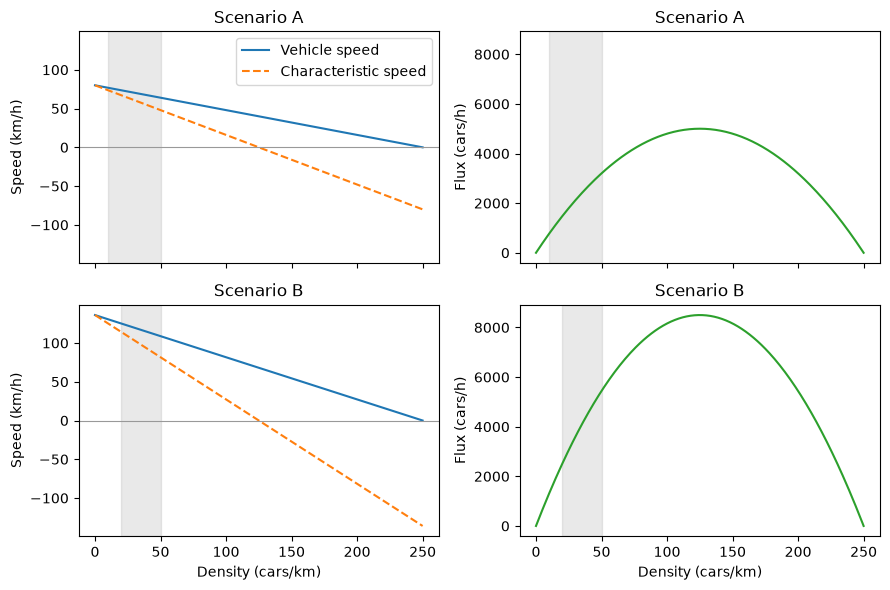

In [2]:
density = np.linspace(0.0, rho_max, 251)
fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True, sharey='col')

for (scenario, (u_max, background)), (ax_speed, ax_flux) in zip(scenarios.items(), axes):
    ax_speed.plot(density, vehicle_speed(density, u_max, rho_max),
                  label='Vehicle speed')
    ax_speed.plot(density, characteristic_speed(density, u_max, rho_max),
                  '--', label='Characteristic speed')
    ax_speed.axhline(0, color='0.6', linewidth=0.8)
    ax_speed.set(title=f'Scenario {scenario}', ylabel='Speed (km/h)')
    ax_flux.plot(density, traffic_flux(density, u_max, rho_max), color='tab:green')
    ax_flux.set(title=f'Scenario {scenario}', ylabel='Flux (cars/h)')
    for ax in (ax_speed, ax_flux):
        ax.axvspan(background, patch_density, color='0.5', alpha=0.17)

axes[0, 0].legend()
for ax in axes[-1]:
    ax.set_xlabel('Density (cars/km)')
fig.tight_layout()
plt.show()

Graphs that model the speed and Flow in each scenario

**Scenarios:**

| Setting | Scenario A | Scenario B |
| :--- | :--- | :--- |
| **Road length** | 11 km | 11 km |
| **Maximum density** $\rho_{\max}$ | 250 cars/km | 250 cars/km |
| **Free-flow speed** $u_{\max}$ | 80 km/h | 136 km/h |
| **Background and left inflow density** | 10 cars/km | 20 cars/km |
| **Dense-patch density** | 50 cars/km | 50 cars/km |
| **Baseline grid and time step** | 51 points, 0.001 h | 51 points, 0.001 h |
| **Speeds to report** | Minimum at 0 min, average at 3 min, minimum at 6 min | Minimum at 0 min, average and minimum at 3 min |


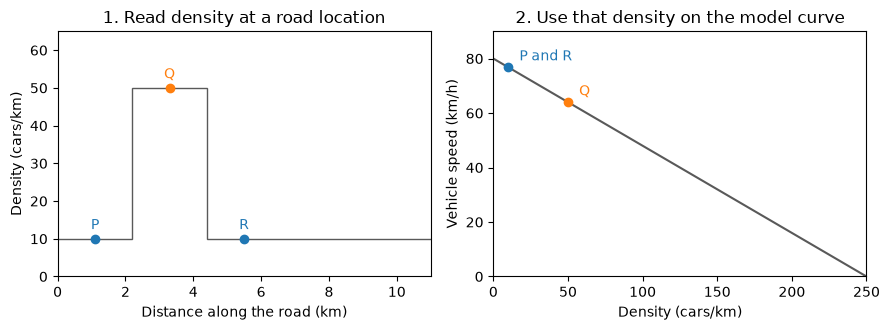

In [3]:
u_max_A, background_A = scenarios['A']
fig_views, (ax_road, ax_curve) = plt.subplots(1, 2, figsize=(9, 3.4))

ax_road.stairs(
    [background_A, patch_density, background_A],
    [0.0, road_length / 5, 2 * road_length / 5, road_length],
    baseline=None, color='0.35',
)
ax_road.set(
    title='1. Read density at a road location',
    xlabel='Distance along the road (km)', ylabel='Density (cars/km)',
    xlim=(0, road_length), ylim=(0, 65),
)

ax_curve.plot(density, vehicle_speed(density, u_max_A, rho_max), color='0.35')
ax_curve.set(
    title='2. Use that density on the model curve',
    xlabel='Density (cars/km)', ylabel='Vehicle speed (km/h)',
    xlim=(0, rho_max), ylim=(0, 90),
)

for label, distance, local_density, color in (
    ('P', 1.1, background_A, 'tab:blue'),
    ('Q', 3.3, patch_density, 'tab:orange'),
    ('R', 5.5, background_A, 'tab:blue'),
):
    ax_road.scatter(distance, local_density, color=color, zorder=3)
    ax_road.annotate(label, (distance, local_density),
                     xytext=(0, 7), textcoords='offset points', ha='center',
                     color=color)

for label, local_density, color in (
    ('P and R', background_A, 'tab:blue'),
    ('Q', patch_density, 'tab:orange'),
):
    speed = vehicle_speed(local_density, u_max_A, rho_max)
    ax_curve.scatter(local_density, speed, color=color, zorder=3)
    ax_curve.annotate(label, (local_density, speed),
                      xytext=(8, 5), textcoords='offset points', color=color)

fig_views.tight_layout()
plt.show()

**Traffic_step** moves the car density forward by one time step (dt) along the road while keeping the left entrance fixed and tracking how many cars cross the ends.

In [4]:
def traffic_step(rho, dx, dt, u_max, rho_max):
    '''Advance one conservative step with a fixed left inlet.'''
    flux = traffic_flux(rho, u_max, rho_max)
    next_rho = rho.copy()
    next_rho[1:] = rho[1:] - (dt / dx) * (flux[1:] - flux[:-1])
    return next_rho, flux[-1] - flux[0]

Testing $[10,50,20]$ and comparing to on paper results

In [5]:
rho_test = np.array([10.0, 50.0, 20.0])
dx_test, dt_test = 1.0, 0.005
rho_next, net_outflow = traffic_step(rho_test, dx_test, dt_test, 80.0, rho_max)
change = dx_test * (rho_next[1:].sum() - rho_test[1:].sum())
print('Updated densities (cars/km):', rho_next)
print(f'Change in discrete total (cars): {change:.2f}')
print(f'Balance residual (cars): {change + dt_test * net_outflow:.2e}')

Updated densities (cars/km): [10.   37.84 28.64]
Change in discrete total (cars): -3.52
Balance residual (cars): 5.33e-15


## Constant State Check Miss

Both versions start with $[10,10,10]$ cars/km. Predict what each will do when both the **flux differences and the density differences are zero**. The first two lines of output tell you whether each version leaves that state unchanged.

Also has one delibrate Mistake subs $u(\rho_i^n)(\rho_i^n - \rho_{i-1}^n)$ in for $F_i^n - F_{i-1}^n$ 

In [6]:
def wrong_traffic_step(rho, dx, dt, u_max, rho_max):
    '''Take a deliberately wrong step using vehicle speed.'''
    next_rho = rho.copy()
    speed = vehicle_speed(rho[1:], u_max, rho_max)
    next_rho[1:] = rho[1:] - (dt / dx) * speed * (rho[1:] - rho[:-1])
    return next_rho


constant = np.full_like(rho_test, rho_test[0])
u_max_A, _ = scenarios['A']
constant_correct, _ = traffic_step(constant, dx_test, dt_test, u_max_A, rho_max)
constant_wrong = wrong_traffic_step(constant, dx_test, dt_test, u_max_A, rho_max)
wrong_next = wrong_traffic_step(rho_test, dx_test, dt_test, u_max_A, rho_max)
wrong_change = dx_test * (wrong_next[1:] - rho_test[1:]).sum()

print('Constant state preserved by conservative step:', np.array_equal(constant_correct, constant))
print('Constant state preserved by wrong step:', np.array_equal(constant_wrong, constant))
print('Wrong update on the hand example (cars/km):', wrong_next)
print(f'Wrong update balance residual (cars): {wrong_change + dt_test * net_outflow:.2f}')

Constant state preserved by conservative step: True
Constant state preserved by wrong step: True
Wrong update on the hand example (cars/km): [10.   37.2  31.04]
Wrong update balance residual (cars): 1.76


**The test successfully showed two things**:
A constant density test had broken code still pass it.
Testing on a non-uniform patch $([10, 50, 20])$ and checking the balance residual immediately exposes the non-conservative mistake (1.76 cars off instead of ~0).

### Time-Stepping Driver Summary

* **Target time ($T > 0$):** Advances the simulation from $t = 0$ to a single requested physical time $T$ (such as $3\text{ min} = 0.05\text{ h}$ or $6\text{ min} = 0.10\text{ h}$).
* **Step count & actual step size:** Rounds $T / \Delta t_{\max}$ **up** to an integer number of steps so the step size stays at or below $\Delta t_{\max}$, then sets the actual step size to $\Delta t = T / n_{\text{steps}}$ so the simulation lands **exactly** on $T$.
* **CFL stability check:** Evaluates the Courant number ($\sigma = a_{\max}\Delta t / \Delta x$) using that actual $\Delta t$ before running the time loop, guarding against time steps that are too large for the grid spacing $\Delta x$.


In [7]:
def traffic_initial_state(N, background):
    '''Build the road grid and the initial density patch.'''
    if N < 5 or N % 5 != 0:
        raise ValueError('Use a positive interval count divisible by five.')
    x = np.linspace(0.0, road_length, N + 1)
    rho = np.full(N + 1, float(background))
    rho[N // 5:2 * N // 5] = patch_density
    return x, rho


def advance_traffic(rho0, dx, t_final, dt_max, u_max, rho_max):
    '''Advance the positive-speed traffic model to one observation time.'''
    if not (dx > 0 and t_final > 0 and dt_max > 0 and u_max > 0 and rho_max > 0):
        raise ValueError('Use positive spacings, times, speed, and maximum density.')
    rho = np.array(rho0, dtype=float, copy=True)
    if rho.ndim != 1 or rho.size < 2 or not np.all(np.isfinite(rho)):
        raise ValueError('Use a finite, one-dimensional density array with at least two points.')
    if rho.min() < 0 or rho.max() >= rho_max / 2:
        raise ValueError('Densities must be at least zero and below half the maximum density.')

    steps = int(np.ceil(t_final / dt_max))
    dt = t_final / steps
    a_max = characteristic_speed(rho.min(), u_max, rho_max)
    cfl = a_max * dt / dx
    if cfl > 1.0:
        raise ValueError('CFL number exceeds one. Choose a smaller maximum time step.')

    net_outflow = 0.0
    for _ in range(steps):
        rho, flux_difference = traffic_step(rho, dx, dt, u_max, rho_max)
        net_outflow += dt * flux_difference

    return {'rho': rho, 'dt': dt, 'steps': steps, 'cfl': cfl,
            'net_outflow': net_outflow, 'work': (rho.size - 1) * steps}

Begin with **50 intervals** and the baseline **maximum step of 0.001 h**. Each call starts from the same initial state for its scenario. Store the returned profiles so you can compare them with finer grids later. The six numbers are baseline estimates. The refinement investigation will show how sensitive they are to the grid and step.

In [8]:
baseline_intervals = 50
baseline_dx = road_length / baseline_intervals
baseline_dt = 0.001
observation_times = {'A': (0.05, 0.10), 'B': (0.05,)}
baseline = {}

for scenario, (u_max, background) in scenarios.items():
    x, rho0 = traffic_initial_state(baseline_intervals, background)
    baseline[scenario] = {'x': x, 'rho0': rho0, 'runs': {}}
    for time in observation_times[scenario]:
        baseline[scenario]['runs'][time] = advance_traffic(
            rho0, baseline_dx, time, baseline_dt, u_max, rho_max
        )

print(f"{'Scenario':<9} {'Time (min)':>10} {'Statistic':>10} {'Speed (m/s)':>12}")
for scenario, time, statistic in (
    ('A', 0.0, 'minimum'), ('A', 0.05, 'average'), ('A', 0.10, 'minimum'),
    ('B', 0.0, 'minimum'), ('B', 0.05, 'average'), ('B', 0.05, 'minimum'),
):
    data = baseline[scenario]
    rho = data['rho0'] if time == 0 else data['runs'][time]['rho']
    u_max, _ = scenarios[scenario]
    speed = vehicle_speed(rho, u_max, rho_max) / 3.6
    value = speed.min() if statistic == 'minimum' else speed.mean()
    print(f'{scenario:<9} {60 * time:10.0f} {statistic:>10} {value:12.3f}')

Scenario  Time (min)  Statistic  Speed (m/s)
A                  0    minimum       17.778
A                  3    average       20.636
A                  6    minimum       18.785
B                  0    minimum       30.222
B                  3    average       33.872
B                  3    minimum       30.986


Over minimum grows over time thus less density, cars going faster

In [9]:
for scenario, data in baseline.items():
    initial = data['rho0']
    initial_total = baseline_dx * initial[1:].sum()
    for time, run in data['runs'].items():
        final = run['rho']
        final_total = baseline_dx * final[1:].sum()
        residual = final_total - initial_total + run['net_outflow']
        balance_tolerance = 1e-12 * (
            abs(initial_total) + abs(final_total) + abs(run['net_outflow'])
        )
        density_tolerance = 1e-12 * initial.max()

        assert final[0] == initial[0], 'The inlet density changed.'
        assert final.min() >= initial.min() - density_tolerance, 'Density fell below the initial range.'
        assert final.max() <= initial.max() + density_tolerance, 'Density exceeded the initial range.'
        assert 0 < run['cfl'] <= 1, 'CFL number outside the supported range.'
        assert abs(residual) <= balance_tolerance, 'Discrete vehicle balance failed.'

        print(f'{scenario}, {60 * time:g} min: CFL = {run["cfl"]:.3f}, '
              f'density = [{final.min():.2f}, {final.max():.2f}] cars/km, '
              f'balance residual = {residual:.2e} cars')

A, 3 min: CFL = 0.335, density = [10.00, 45.54] cars/km, balance residual = -1.34e-14 cars
A, 6 min: CFL = 0.335, density = [10.00, 38.67] cars/km, balance residual = 4.80e-14 cars
B, 3 min: CFL = 0.519, density = [20.00, 44.94] cars/km, balance residual = 6.14e-14 cars


Our **Balance residual must be close to zero** to prove the **telescope works properly** and there were **no cars that were created or destroyed**

## Density along the Road

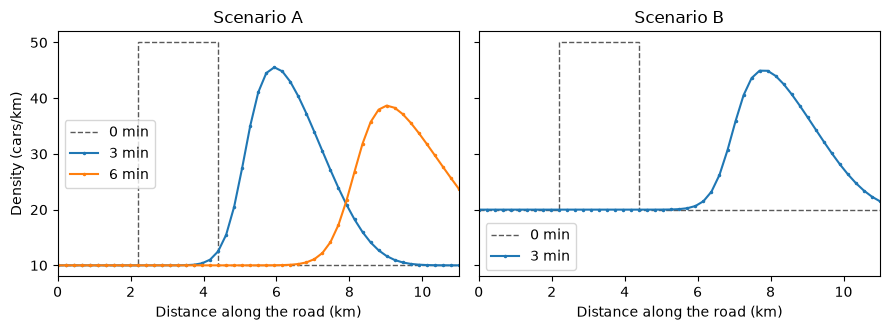

In [10]:
fig_baseline, axes_baseline = plt.subplots(
    1, 2, figsize=(9, 3.4), sharex=True, sharey=True,
)

for ax, (scenario, data) in zip(axes_baseline, baseline.items()):
    _, background = scenarios[scenario]
    ax.stairs(
        [background, patch_density, background],
        [0.0, road_length / 5, 2 * road_length / 5, road_length],
        baseline=None, color='0.35', linestyle='--', label='0 min',
    )
    for time, run in data['runs'].items():
        ax.plot(data['x'], run['rho'], marker='.', markersize=3,
                label=f'{60 * time:g} min')
    ax.set(title=f'Scenario {scenario}', xlabel='Distance along the road (km)',
           xlim=(0, road_length))
    ax.legend()

axes_baseline[0].set_ylabel('Density (cars/km)')
fig_baseline.tight_layout()
plt.show()

### Refinement Agent Brief

# Traffic Simulation Grid & Time-Step Refinement Study — Agent Brief

---

## 1. Goal
Evaluate how spatial grid and time-step refinement across **50 to 1,600 intervals** (51 to 1,601 grid points) affects the conservative Greenshields traffic simulation, distinguishing genuine physical evolution (downstream wave propagation, edge asymmetry, and boundary exit) from coarse-grid numerical smearing—specifically on peak density and minimum vehicle speed versus spatial average speed—and testing sensitivity to grid spacing and time-step halving using a `< 0.1 m/s` criterion.

---

## 2. Scope
* **Road & Model Constants:** Road length $L = 11.0\text{ km}$, maximum density $\rho_{\max} = 250.0\text{ cars/km}$, initial patch density $\rho_{\text{patch}} = 50.0\text{ cars/km}$.
* **Scenarios & Observation Times:**
  * **Scenario A** ($u_{\max} = 80.0\text{ km/h}$, $\rho_{\text{bg}} = 10.0\text{ cars/km}$): observed at **$3\text{ min}$ ($0.05\text{ h}$)** and **$6\text{ min}$ ($0.10\text{ h}$)**.
  * **Scenario B** ($u_{\max} = 136.0\text{ km/h}$, $\rho_{\text{bg}} = 20.0\text{ cars/km}$): observed at **$3\text{ min}$ ($0.05\text{ h}$)**.
* **Grid Refinement Ladder:** Interval counts $N \in \{50, 100, 200, 400, 800, 1600\}$ (corresponding to $51$ through $1,601$ grid points), with spatial spacing $\Delta x = L / N$ computed from the interval count.
* **Time-Step Refinement Schedule:** Start from a maximum time step $\Delta t_{\max} = 0.001\text{ h}$ on $N = 50$ intervals and **halve $\Delta t_{\max}$ each time the interval count doubles** ($0.001 \to 0.0005 \to 0.00025 \to 0.000125 \to 0.0000625 \to 0.00003125\text{ h}$).
* **Initial Patch:** Keep the same physical dense patch (`50.0 cars/km` on `[2.2 km, 4.4 km)`, i.e., indices `N // 5 : 2 * N // 5` in `traffic_initial_state`) across all grids and scenarios.
* **Sensitivity & Candidate Study:** Compare adjacent grid pairs at positive observation times (`3 min`, `6 min`), select a candidate grid per scenario via two consecutive passing pairs (`< 0.1 m/s` unrounded), and run a fixed-grid time-step halving check (`dt_max` vs. `0.5 * dt_max`) on each candidate grid at the same positive observation times.

---

## 3. Context and Assumptions
* **Existing Notebook Definitions to Reuse:**
  * Constants & scenario dictionary: `road_length = 11.0`, `rho_max = 250.0`, `patch_density = 50.0`, `scenarios = {'A': (80.0, 10.0), 'B': (136.0, 20.0)}`.
  * Speed & flux functions: `vehicle_speed(rho, u_max, rho_max)`, `traffic_flux(rho, u_max, rho_max)`, `characteristic_speed(rho, u_max, rho_max)`.
  * Step & initializer functions: `traffic_step(rho, dx, dt, u_max, rho_max)`, `traffic_initial_state(N, background)`, and `advance_traffic(rho0, dx, t_final, dt_max, u_max, rho_max)` (note: `wrong_traffic_step` exists in the notebook for reference/error comparison and is **not** used for the conservative study).
* **Unit Conversion:** `vehicle_speed` returns speeds in $\text{km/h}$; convert to $\text{m/s}$ (`speed / 3.6`) **before** computing any summary changes or profile differences.
* **Independent Starts & Baseline Reuse:** Every run starts fresh from the scenario's initial density array `rho0` produced by `traffic_initial_state(N, background)` with spacing `dx = road_length / N`. If a saved `baseline` matches the brief's scenario, observation time, grid (`N = 50`), spacing (`11.0 / 50`), and `dt_max = 0.001`, reuse it rather than recomputing redundantly.
* **Nested Grid Alignment & Error Masking:** Because interval counts double across consecutive grids, every second fine-grid point (`fine[::2]`) coincides spatially with a coarse-grid point, including both endpoints ($x = 0$ and $x = 11.0\text{ km}$). Absolute speed differences must be taken before spatial averaging so positive and negative differences cannot cancel, and a small whole-road trapezoidal average $D$ can still conceal a localized change near a steep edge.
* **Sensitivity Interpretation & Human Ownership:** The `< 0.1 m/s` check measures sensitivity to grid and time-step refinement. Final **resolution judgment** on discrepancies and **physical/analytical interpretation** belong strictly to the user.

---

## 4. Interface and Outputs
* **Retained Data per Run** (for each scenario, grid `N`, and observation time):
  * Spatial positions `x` (`N + 1` points), initial density array `rho0`, and final density array `rho`.
  * Solver diagnostics from `advance_traffic`: actual step `dt`, CFL number `cfl`, step count `steps`, point-update count `work`, and `net_outflow`.
* **Required Run Table:** Report for every run:
  * Interval count (`N`), observation time (`t_final` in minutes and/or hours), actual step (`dt`), CFL number (`cfl`), step count (`steps`), and point-update count (`work`) (along with scenario/grid context as needed).
* **Required Comparison Table:** Compute all values directly from the **retained arrays** (`x`, `rho0`, `rho`) after converting speeds to $\text{m/s}$:
  * **Adjacent Grid Pair Comparisons** at positive observation times (`3 min` and `6 min` for Scenario A; `3 min` for Scenario B):
    * Applicable speed summary changes in $\text{m/s}$ (`|Δu_avg|` at `3 min` in Scenario A; `|Δu_min|` at `6 min` in Scenario A; `|Δu_avg|` and `|Δu_min|` at `3 min` in Scenario B).
    * Whole-road trapezoidal average $D$ in $\text{m/s}$ over shared coarse nodes $i = 0, \dots, N$ using coarse spacing $\Delta x = L / N$:
      $$D = \frac{\Delta x}{L}\left(\frac{1}{2}d_0 + \sum_{i=1}^{N-1} d_i + \frac{1}{2}d_N\right), \quad d_i = |u_{\text{fine}, 2i} - u_{\text{coarse}, i}|$$
    * Pass/fail indicator (`True` only if every applicable summary change and every profile average $D$ is strictly less than `0.1 m/s`, using unrounded values).
  * **Candidate Grid & Fixed-Grid Time-Step Halving Comparisons:**
    * Selected candidate grid per scenario (the finer grid of the second of the first two consecutive passing pairs).
    * Comparison on the candidate grid at the same positive observation times between `dt_max` and `0.5 * dt_max` across **all grid points directly** (since the grid is identical): applicable summary changes in $\text{m/s}$, all-point profile average in $\text{m/s}$, and pass/fail against `< 0.1 m/s` (unrounded).
  * **Unresolved Measure Reporting:** If grid refinement or time-step halving fails to produce a passing result, explicitly list which specific measure(s) remain at or above `0.1 m/s` within the tested runs.

---

## 5. Required Behavior
1. **Restate & Resolve First:** Before drafting any code, restate the experiment and flag/resolve any ambiguities or differences with the user.
2. **Preserve Existing Notebook Structure:** Keep the supplied solver, definitions, and earlier notebook cells intact.
3. **Add Only Unexecuted Cells:** When adding cells to the notebook, append **only unexecuted experiment cells** after this section—do not execute new cells automatically.
4. **Chat Fallback:** If working in chat rather than modifying notebook cells directly, output clean, inspectable cell blocks ready to review and paste.
5. **Strict Metric & Threshold Rules:** Convert speeds to $\text{m/s}$ before differencing; take absolute differences before averaging; evaluate `< 0.1 m/s` on **unrounded** values; start each run from the scenario's initial patch with `dx = road_length / N`; reuse matching saved baseline data when valid.
6. **Defer Judgment & Interpretation:** Present computed numbers, diagnostics, pass/fail checks, and any unresolved measures clearly, while leaving resolution judgment and physical/analytical interpretation to the user.

---

## 6. Rejected Requests
* **Do not** alter, overwrite, or delete the supplied `advance_traffic`, `traffic_step`, `wrong_traffic_step`, `traffic_initial_state`, speed/flux functions, or earlier notebook cells.
* **Do not** execute newly created experiment cells automatically without explicit instruction.
* **Do not** chain runs from a prior observation time instead of starting each run from the scenario's initial patch `rho0`.
* **Do not** round metrics prior to testing the `< 0.1 m/s` threshold, or average signed differences before taking absolute values.
* **Do not** treat a small whole-road average $D$ as proof against localized edge changes, or treat `< 0.1 m/s` sensitivity as exact continuum convergence.
* **Do not** usurp the user's resolution judgment or final physical/analytical interpretation.

---

## 7. Accepted Evidence
* Exact adherence to the notebook's existing functions (`traffic_initial_state`, `advance_traffic`, `vehicle_speed`) and parameter/time-step halving schedule (`50` to `1,600` intervals; $\Delta t_{\max}$ halved from `0.001 h` on each doubling).
* Retained arrays (`x`, `rho0`, `rho`) and solver diagnostics (`dt`, `cfl`, `steps`, `work`, `net_outflow`) for every scenario, grid, and positive observation time.
* Complete **run table** and **comparison table** (adjacent coarse-to-fine grid pairs over shared nodes + candidate grid `dt_max` vs. `0.5 * dt_max` over all points) with all speeds in $\text{m/s}$ and comparisons evaluated on unrounded values against `< 0.1 m/s`.
* Clear identification of the candidate grid (finer grid of the second of the first two consecutive passing pairs) and explicit reporting of any unresolved measures if either stage does not pass.
* Clean, unexecuted notebook cells placed after this section (or inspectable paste-ready blocks in chat) with supplied/earlier cells untouched.

---

## 8. Agent Permissions
* **Allowed:**
  * Restate the experiment, surface discrepancies/questions, and propose resolutions for user confirmation before coding.
  * Reuse matching saved `baseline` results and invoke `traffic_initial_state`, `advance_traffic`, and `vehicle_speed` with their defined signatures.
  * Compute metrics and diagnostics from retained arrays and assemble the requested run and comparison tables.
  * Append **unexecuted** experiment cells after the reference section (or provide inspectable cell blocks in chat).
* **Not Allowed:**
  * Modifying the supplied solver or earlier cells.
  * Automatically executing newly added cells.
  * Making final resolution judgments on ambiguities or claiming final analytical/physical interpretations on the user's behalf.
